In [1]:
import keras
import matplotlib.pyplot as plt

TRAIN_DIR = "/Users/alfadhul/Downloads/03_Machine_Learning/NN_CL_LAB/train"
TEST_DIR = "/Users/alfadhul/Downloads/03_Machine_Learning/NN_CL_LAB/test"

In [2]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32,
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=42)

val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32,
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=42)

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32,
    label_mode="int",
    shuffle=False)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.


In [3]:
print("Classes:", train_ds.class_names)

for X, y in train_ds.take(1):
    print("X shape:", X.shape)
    print("y shape:", y.shape)

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
X shape: (32, 48, 48, 1)
y shape: (32,)


In [4]:
import numpy as np
import pandas as pd
y_train = np.concatenate([
    y.numpy() for X, y in train_ds
])
y_true = np.concatenate([y.numpy() for X, y in test_ds])

In [5]:
class_counts = pd.Series(y_train).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "emotion": train_ds.class_names,
    "count": class_counts.values})

class_distribution

,emotion,count
0,angry,3218
1,disgust,363
2,fear,3285
3,happy,5813
4,neutral,3965
5,sad,3834
6,surprise,2490


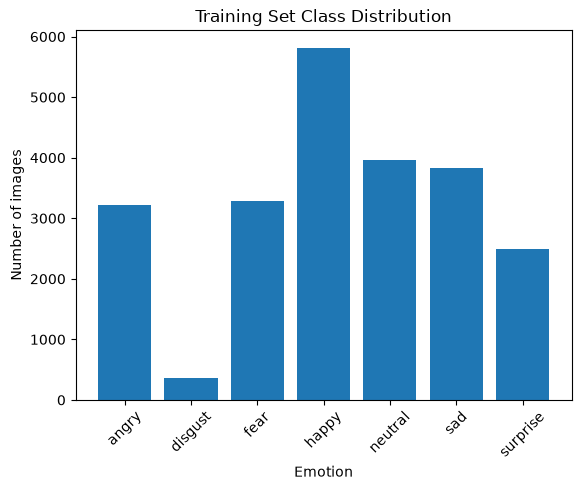

In [6]:
plt.bar(
    class_distribution["emotion"],
    class_distribution["count"]
)
plt.xlabel("Emotion")
plt.ylabel("Number of images")
plt.title("Training Set Class Distribution")
plt.xticks(rotation=45)
plt.show()

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Activation, Flatten, Input, Rescaling

In [8]:
model = Sequential([
    Input(shape=(48, 48)),
    Rescaling(1./255),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(100, activation='relu'),
    Dense(50, activation='relu'),
    Dense(7, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', metrics=['acc'])

history=model.fit(train_ds, validation_data=val_ds, epochs=10, shuffle=False)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.2598 - loss: 1.8215 - val_acc: 0.2890 - val_loss: 1.7457
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3091 - loss: 1.7278 - val_acc: 0.2904 - val_loss: 1.7433
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.3309 - loss: 1.6933 - val_acc: 0.3289 - val_loss: 1.6693
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.3424 - loss: 1.6683 - val_acc: 0.3578 - val_loss: 1.6482
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3506 - loss: 1.6501 - val_acc: 0.3599 - val_loss: 1.6353
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - acc: 0.3594 - loss: 1.6357 - val_acc: 0.2797 - val_loss: 1.7878
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3612 - loss: 1.6247 - val_acc: 0.3625 - val_loss: 1.6313
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3683 - loss: 1.6110 - val_acc: 0.3656 - val_loss: 1.6243
Epoch 9/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - ac

In [9]:
history_df= pd.DataFrame(history.history)

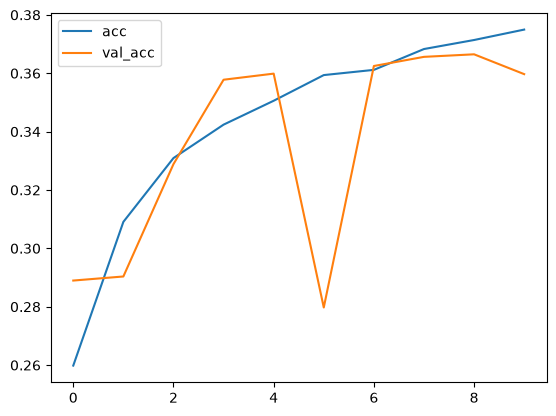

In [10]:
history_df[['acc', 'val_acc']].plot();

In [11]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train)

class_weight_dict = dict(zip(classes, weights))

print(class_weight_dict)

{np.int32(0): np.float64(1.0196217703986505), np.int32(1): np.float64(9.03896103896104), np.int32(2): np.float64(0.998825831702544), np.int32(3): np.float64(0.5644491410877098), np.int32(4): np.float64(0.8275265717888669), np.int32(5): np.float64(0.8558014755197854), np.int32(6): np.float64(1.3177280550774526)}


In [12]:
from keras.optimizers import Adam
model = Sequential([
    Input(shape=(48, 48)),
    Rescaling(1./255),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(100, activation='relu'),
    Dense(50, activation='relu'),
    Dense(7, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer = Adam(learning_rate=0.0005), metrics=['acc'])

history=model.fit(train_ds, validation_data=val_ds, epochs=10, shuffle=False, class_weight=class_weight_dict)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.1455 - loss: 1.9527 - val_acc: 0.2822 - val_loss: 1.8576
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - acc: 0.2462 - loss: 1.8814 - val_acc: 0.2851 - val_loss: 1.8302
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.2610 - loss: 1.8486 - val_acc: 0.2703 - val_loss: 1.8156
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - acc: 0.2590 - loss: 1.8277 - val_acc: 0.1951 - val_loss: 1.9121
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.2629 - loss: 1.8103 - val_acc: 0.2815 - val_loss: 1.8150
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.2764 - loss: 1.7908 - val_acc: 0.3102 - val_loss: 1.7581
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.2800 - loss: 1.7797 - val_acc: 0.3168 - val_loss: 1.7454
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - acc: 0.2894 - loss: 1.7565 - val_acc: 0.2930 - val_loss: 1.7844
Epoch 9/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - ac

In [14]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

callbacks = [
    ModelCheckpoint(
        "emotion_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"),
    EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True)]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=callbacks)

Epoch 1/50


 17/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - acc: 0.3511 - loss: 1.7452  

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3025 - loss: 1.7290 - val_acc: 0.2912 - val_loss: 1.7627
Epoch 2/50
 18/718 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - acc: 0.3160 - loss: 1.7148 

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/callbacks/model_checkpoint.py:329: UserWarning: Can save best model only with val_accuracy available.
  if self._should_save_model(epoch, batch, logs, filepath):
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/callbacks/early_stopping.py:100: UserWarning: Early stopping conditioned on metric `val_accuracy` which is not available. Available metrics are: acc,loss,val_acc,val_loss
  current = self.get_monitor_value(logs)


718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3042 - loss: 1.7121 - val_acc: 0.2984 - val_loss: 1.7475
Epoch 3/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3110 - loss: 1.6962 - val_acc: 0.2844 - val_loss: 1.7778
Epoch 4/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3076 - loss: 1.6935 - val_acc: 0.2958 - val_loss: 1.7454
Epoch 5/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3191 - loss: 1.6709 - val_acc: 0.2916 - val_loss: 1.7540
Epoch 6/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3228 - loss: 1.6583 - val_acc: 0.3181 - val_loss: 1.7192
Epoch 7/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3285 - loss: 1.6443 - val_acc: 0.2757 - val_loss: 1.7835
Epoch 8/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3261 - loss: 1.6424 - val_acc: 0.2907 - val_loss: 1.7524
Epoch 9/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3248 - loss: 1.6343 - val_acc: 0.3198 - val_loss: 1.7078
Epoch 10/50
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3346 

In [15]:
from keras.models import load_model

model = load_model("emotion_model.keras")
y_pred = np.argmax(model.predict(test_ds), axis=1)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [16]:
y_true = np.concatenate([y.numpy() for X, y in test_ds])

              precision    recall  f1-score   support

       angry       0.21      0.22      0.22       958
     disgust       0.08      0.43      0.14       111
        fear       0.18      0.21      0.19      1024
       happy       0.58      0.38      0.46      1774
     neutral       0.33      0.31      0.32      1233
         sad       0.29      0.28      0.29      1247
    surprise       0.45      0.49      0.47       831

    accuracy                           0.32      7178
   macro avg       0.30      0.33      0.30      7178
weighted avg       0.36      0.32      0.33      7178



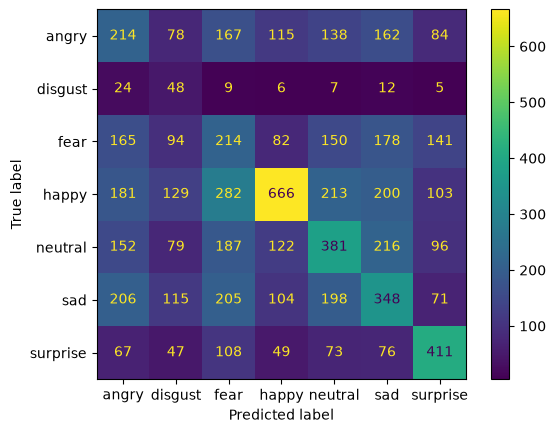

In [17]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
print(classification_report(y_true,
    y_pred, target_names=test_ds.class_names))
ConfusionMatrixDisplay.from_predictions(y_true,
    y_pred, display_labels=test_ds.class_names)